In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.close()
import matplotlib as mpl
from matplotlib import gridspec

from matplotlib.patches import FancyArrowPatch
from matplotlib.gridspec import GridSpec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

from brokenaxes import brokenaxes

mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False
import os
import pickle5 as pickle
import csv
from scipy.optimize import curve_fit
from scipy.signal import savgol_filter, find_peaks

import import_ipynb
import ipynb.fs.full.ssiProjectModule2 as ssiMod

from tqdm.notebook import tqdm
import sys

import importlib as imp
imp.reload(ssiMod)

from scipy.stats import wilcoxon as w
from scipy.special import factorial
from scipy.stats import circmean
from scipy.stats import circstd
from scipy.stats import ks_2samp
import math
import statsmodels.stats.api as sms

from multiprocessing import Pool
from functools import partial

from mpl_toolkits.axes_grid1.inset_locator import inset_axes

from datetime import datetime
import bisect


main_dir = '/home/cparis/00PhD/DS_PCBreview/'


def plot_circle(ax, angle_deg, R=1.0):
    # Convert angle to radians
    theta = np.deg2rad(angle_deg)
    
    # Arrow endpoint
    x = R * np.cos(theta)
    y = R * np.sin(theta)

    
    # Draw circle of radius R
    circle = plt.Circle((0, 0), R, fill=False)
    ax.add_patch(circle)

    
    # Formatting
    ax.set_aspect('equal', adjustable='datalim')  # tightly fit
    ax.autoscale_view()   
#     ax.set_xlim(-1.2*R, 1.2*R)
#     ax.set_ylim(-1.2*R, 1.2*R)
    ax.axhline(0,  alpha = 0.5)
    ax.axvline(0,  alpha = 0.5)
    ax.grid(False)
    ax.axis('off')

#     plt.show()

def draw_arrow(ax, x0,y0, th, l):
        # Draw arrow from origin
    ax.arrow(x0, y0, l*np.cos(np.deg2rad(th)), l*np.sin(np.deg2rad(th)), 
             length_includes_head=True,
             head_width=0.02, 
             head_length=0.02,
             facecolor = 'k')

def draw_ellipse(ax, a, b):
    # Parameter t
    t = np.linspace(0, 2*np.pi, 400)
    
    # Ellipse parametric equations
    x = a * np.cos(t)
    y = b * np.sin(t)
    
    # Plot
#     plt.figure()
    plt.plot(x, y, linestyle='dashed', alpha = 0.5, color = 'grey')
    plt.gca().set_aspect('equal', adjustable='box')
    
    # Axes and grid
#     plt.title(f"Ellipse with radii a={a}, b={np.around(b,2)}")

def complex_from_polar(k, theta):
    return k * np.exp(1j * np.deg2rad(theta))

def flow_ellipse_axis(x,y, Ry=1):
#     returns the minor ellipse axis along the x axis
    if y==Ry:
        return Ry/2  #arbitrary value
    else:
        return x/np.sqrt(1.-(y/Ry)**2)

def ellipse_slope_in_xy(x,y,Rx,Ry):
    if Rx==0:
        return -np.inf*np.sign(y)  #case where ellipse is collapsed onto a segment [-Ry, Ry]
    elif y==0:
        return -np.sign(x)*np.inf
    else:
        return -(x/y)*(Ry/Rx)**2 


def flow_in_point_of_ellipse_horizontal(x,z, x_ax, z_ax, arrow_len, hor_comp_th):
#     NOTE: MODIFICATION OF LENGTH:
#           Consider 2 arrows at same source point, one pointing towards a pole, other pointing away from it
#           The arrow pointing towards will appear shorter when projected because of sphere curvature
#           This is coded in "np.sign(phi*x)*delta_arc" term

    slope_h = ellipse_slope_in_xy(x,z, a_ax, z_ax)
    if np.abs(slope_h)!=np.inf:
        mod_dir_h = np.arctan(slope_h)+(1-np.sign(hor_comp_th))*np.pi/2*np.abs(np.sign(hor_comp_th))
    else: mod_dir_h = np.pi/2 - np.pi/2*np.sign(hor_comp_th)
    lmbda = np.arctan(z/x) if x!=0 else 0.
    phi = np.arccos(np.sqrt(x**2+z**2)/R)
    hor_flow_amp =  np.abs(arrow_len)*np.sqrt(1-np.cos(phi-np.sign(hor_comp_th*x)*delta_arc)**2*np.cos(lmbda)**2)
    print(mod_dir_h)
    return mod_dir_h, hor_flow_amp

def optic_flow_mod(theta, x0, z0):
    # horizontal and vertical components of stimulus direction 
    #(along naso-temporal and dorso-ventral axes, respectively)
    hor_comp_th,vert_comp_th = np.cos(theta), np.sin(theta)
    hor_arrow_len, vert_arrow_len = 0.2*hor_comp_th, 0.2*vert_comp_th

    # Naso-temporal flow ellipse - along x axis (ah=1)
    hor_a, hor_b = 1, flow_ellipse_axis(z0,x0)
    vert_b, vert_a = 1, flow_ellipse_axis(x0,z0)
    
    for x in [x0]:
        z = hor_b*np.sqrt(1.-(x/hor_a)**2)
        th1, l1 = flow_in_point_of_ellipse_horizontal(x,z, hor_a, hor_b, hor_arrow_len, hor_comp_th)
    for z in [z0]:
        x = vert_a*np.sqrt(1.-(z/vert_b)**2)
        th2, l2 = flow_in_point_of_ellipse_vertical(x,z, vert_a, vert_b, vert_arrow_len, vert_comp_th)
    final = l1*np.exp(1j*th1) + l2*np.exp(1j*th2)
    return np.sqrt(final.real**2+final.imag**2), np.rad2deg(np.angle(final))%360

def flow_ellipse_axis(x,y, Ry=1):
#     returns the minor ellipse axis along the x axis
    if y==Ry:
        return Ry/2  #arbitrary value
    else:
        return x/np.sqrt(1.-(y/Ry)**2)

def ellipse_slope_in_xy(x,y,Rx,Ry):
    if Rx==0:
        return -np.inf*np.sign(y)  #case where ellipse is collapsed onto a segment [-Ry, Ry]
    elif y==0:
        return -np.sign(x)*np.inf
    else:
        return -(x/y)*(Ry/Rx)**2 


def flow_in_point_of_ellipse(x,z, x_ax, z_ax, flow_parallel_comp, which, delta_arc = np.deg2rad(15)):
#     NOTE: MODIFICATION OF LENGTH:
#           Consider 2 arrows at same source point, one pointing towards a pole, other pointing away from it
#           The arrow pointing towards will appear shorter when projected because of sphere curvature
#           This is coded in "np.sign(phi*x)*delta_arc" term
    lmbda = np.arctan(z/x) if x!=0 else -np.sign(z)*np.pi
    phi = np.arccos(np.sqrt(x**2+z**2)/R)
    slope_h = ellipse_slope_in_xy(x,z, x_ax, z_ax)
    if np.abs(slope_h)!=np.inf:
        new_theta = np.arctan(slope_h)+(1+np.sign(flow_parallel_comp*x*z))*np.pi/2*np.abs(np.sign(flow_parallel_comp))
        if which=='h':
            new_theta = -new_theta+np.pi/2
    elif np.abs(slope_h)==np.inf and which=='h': 
        new_theta = np.pi/2 - np.pi/2*np.sign(flow_parallel_comp)
#         new_theta = np.pi/2*np.sign(flow_parallel_comp)

    elif np.abs(slope_h)==np.inf and which=='v': 
        new_theta = np.pi/2*np.sign(flow_parallel_comp)
        
    amplitude_mod = np.sqrt(1.-np.cos(phi-np.sign(flow_parallel_comp*z)*delta_arc)**2\
                            *np.sin(lmbda+np.sign(flow_parallel_comp*x)*delta_arc)**2) 

#     if which=='v':
#         amplitude_mod = np.sqrt(1-np.cos(phi-np.sign(flow_parallel_comp*z)*delta_arc)**2*np.cos(lmbda)**2)        
#     elif which=='h':
#         amplitude_mod = np.sqrt(1-np.cos(phi-np.sign(flow_parallel_comp*z)*delta_arc)**2*np.cos(lmbda)**2) 
    return np.abs(flow_parallel_comp)*amplitude_mod, np.rad2deg(new_theta)


def FTVM_dx(th, a, th_0, s, baseline, g):           #indexed with 'ftvm'
    '''Modified Von Mises function\n Parameters Area, mean, concentration, baseline, flatness\n g = 0 gives Von Mises function'''
    '''This version computes the FTVM on a non-uniform dx support, preserving the area under the curve'''
#     get average bins size centered in th[i]: dx[i] = (x[i+1]-x[i-1])/2
    delta_th = (180-np.abs(180-np.abs((np.roll(th, -1) - np.roll(th, 1)))))/2  
#     print(delta_th)
#     get ftvm function value at th[i]
    ftvm_f = np.exp(np.float64((np.cos(np.deg2rad(th-th_0-g*np.sin(np.deg2rad(th-th_0))))-1)/s))
    
    res = (a*ftvm_f/ np.sum(ftvm_f*delta_th/(360/36)) + baseline) 
    return res+np.any(res<0.)*1e10


def direction_deformation(vector, x0,z0, R=1, arrow_len=0.15):
    vert_b, vert_a = R, flow_ellipse_axis(x0,z0)
    hor_a, hor_b = R, flow_ellipse_axis(z0,x0)
    
    for theta in np.deg2rad(vector):
        # upward arrow at (0,0)
        ax.arrow(0, 0, arrow_len*np.cos(theta),arrow_len*np.sin(theta), 
             head_width=arrow_len/5, head_length=arrow_len/3, fc='k', ec='k')
        l_mod_z, th_mod_z = flow_in_point_of_ellipse(x0,z0, vert_a, vert_b, arrow_len*np.sin(theta), 'v')
        l_mod_x, th_mod_x = flow_in_point_of_ellipse(z0,x0, hor_b, hor_a, arrow_len*np.cos(theta), 'h')

        resultant = l_mod_x*np.exp(1j*np.deg2rad(th_mod_x)) + l_mod_z*np.exp(1j*np.deg2rad(th_mod_z))
        final_arr = np.append(final_arr, resultant)

    final_l, final_th = np.sqrt(final_arr.real**2+final_arr.imag**2), np.rad2deg(np.angle(final_arr))%360 

#     print(final_th.shape)
    new_vector = final_l*np.exp(1j*np.deg2rad(final_th))
    return final_l, final_th, new_vector

/home/cparis/anaconda3/lib/python3.7/site-packages/statsmodels/compat/pandas.py:49: FutureWarning: The Panel class is removed from pandas. Accessing it from the top-level namespace will also be removed in the next version
  data_klasses = (pandas.Series, pandas.DataFrame, pandas.Panel)


0
1
2
3
0
1
2
3
(4,)


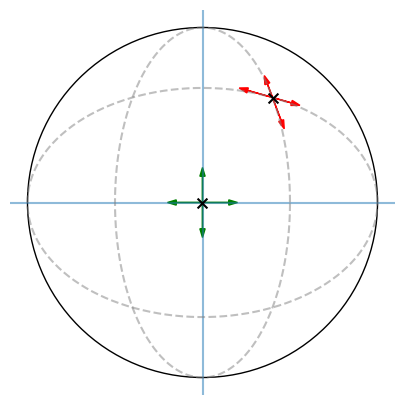

In [2]:
R=1
theta = np.deg2rad(-45)
hor_comp_th,vert_comp_th = np.cos(theta), np.sin(theta)
arrow_len = 0.2
delta_arc = np.deg2rad(10)

mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False
mpl.rcParams['axes.spines.left'] = False
mpl.rcParams['axes.spines.bottom'] = False
# circle and vertical ellipse
x0, z0 = 0.4,0.6
vert_b, vert_a = 1, flow_ellipse_axis(x0,z0)
hor_a, hor_b = 1, flow_ellipse_axis(z0,x0)

fig, ax = plt.subplots(figsize=(5, 5))

plot_circle(ax, 90, 1)
draw_ellipse(ax, vert_a, vert_b)
draw_ellipse(ax, hor_a, hor_b)


# # upward arrow at (x0,z0)
# ax.arrow(0, 0, arrow_len*np.cos(theta),arrow_len*np.sin(theta), 
#          head_width=0.03, head_length=0.05, fc='k', ec='k')

# point
ax.scatter(x0, z0, s=50, c='k', zorder = 5, marker='x')
ax.scatter(-0.0001, 0, s=50, c='k', zorder = 5, marker='x')

fine_stim = np.arange(0,360,0.2)
stim_step = 2
stim = np.arange(0,360,stim_step)
#------uniform prior-----
th_prior = np.ones_like(stim)/(np.ones_like(stim)*stim_step).sum()
# -----------------------
arrow_len = 0.15
mod_prior = np.array([])

final_arr = np.array([])
fine_stim = np.arange(0,360,90)

for idx, theta in enumerate(np.deg2rad(fine_stim)):
    # upward arrow at (0,0)
    if idx % (fine_stim.size//4)==0:
        if idx%(fine_stim.size//4)==0:
            print(idx)
            arrowcolor='green'
        else: arrowcolor='limegreen'
        ax.arrow(0, 0, arrow_len*np.cos(theta),arrow_len*np.sin(theta), 
             head_width=0.03, head_length=0.05, fc=arrowcolor, ec=arrowcolor)
    l_mod_z, th_mod_z = flow_in_point_of_ellipse(x0,z0, vert_a, vert_b, arrow_len*np.sin(theta), 'v')
    l_mod_x, th_mod_x = flow_in_point_of_ellipse(z0,x0, hor_b, hor_a, arrow_len*np.cos(theta), 'h')
    
    resultant = l_mod_x*np.exp(1j*np.deg2rad(th_mod_x)) + l_mod_z*np.exp(1j*np.deg2rad(th_mod_z))
    final_arr = np.append(final_arr, resultant)

final_l, final_th = np.sqrt(final_arr.real**2+final_arr.imag**2), np.rad2deg(np.angle(final_arr))%360 


for idx, arr in enumerate(final_l*np.exp(1j*np.deg2rad(final_th))):
    if idx % (fine_stim.size//4)==0:
        if idx%(fine_stim.size//4)==0:
            print(idx)
            arrowcolor='red'
        else: 
            arrowcolor='tomato'
    else: continue
    ax.arrow(x0, z0, arr.real, arr.imag,
         head_width=0.03, head_length=0.05, fc=arrowcolor, ec=arrowcolor)
# (x0,z0) point
# plt.savefig(main_dir+f'1Optic_flow_direction_distortion_[{x0,z0}].jpg', bbox_inches = 'tight', dpi = 300)
print(final_th.shape)

roll_idx = final_th.argmin()

d_xi = np.roll(np.abs(180-np.abs(180-np.abs((np.roll(np.roll(final_th, -roll_idx), -1) \
                                      - np.roll(np.roll(final_th, -roll_idx), 1)))))/2, roll_idx)


xi_stim = np.roll(final_th, -roll_idx).reshape(-1,max(int(fine_stim.size/stim.size),fine_stim.size)).mean(axis=1)

hist_prior = np.histogram(np.roll(final_th, -roll_idx), range = (0,360), bins = 180, density = True)[0]
mpl.rcParams['axes.spines.left'] = True
mpl.rcParams['axes.spines.bottom'] = True


dict_keys(['all_multipliers', 'all_quad_pars', 'all_quad_tc', 'all_ssis', 'all_quad_fwhm', 'exp_quad_list', 'all_quad_vm_fit_pars', 'all_quad_raw_mean_tcs', 'all_quad_raw_mean_stds', 'original_cell_idx_quads'])


(0.0, 100.0)

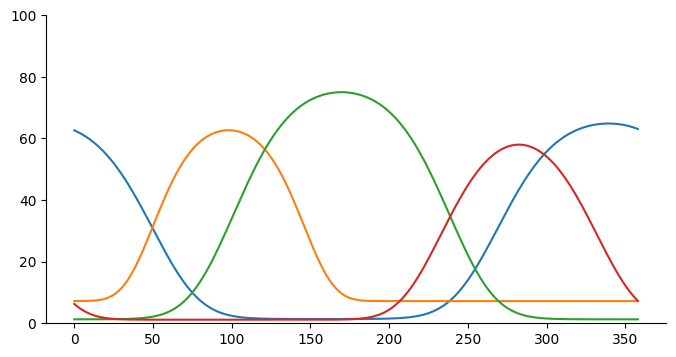

In [3]:
output_dir = '/home/cparis/00PhD/DS_PCBreview/'

theta_step = 2
main_dir = '/home/cparis/00PhD/'

area_or_max = 'Area'
dat_dir_out = main_dir + f'Simulated Stretch/Analyze stretched quadruplets constrained by AREA or MAX/'

title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_original_g_20240509_AREA.pkl'
# title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_original_g_20240506_MAX.pkl'


with open(dat_dir_out+title, 'rb') as rick:
    data_dict = pickle.load(rick)
print(data_dict.keys())


stim = np.arange(0,360,theta_step)

example = 201
bio_idx = np.where(data_dict['all_multipliers']==1)[0][0]
example_quad_pars_og = data_dict['all_quad_pars'][example]
example_quad_tc = np.array([ssiMod.FTVM_dx(stim, *pars) for pars in example_quad_pars_og[bio_idx]])

plt.figure(figsize = (8,4))
plt.plot(stim, example_quad_tc.T)
plt.ylim(0,100)

In [4]:
import ipynb.fs.full.ssiProjectModule2 as ssiMod
import importlib as imp
imp.reload(ssiMod)

<module 'ipynb.fs.full.ssiProjectModule2' (/home/cparis/00PhD/DS_PCBreview/ssiProjectModule2.ipynb)>

In [5]:
x0, z0 = 0.4,0.6
vert_b, vert_a = 1, flow_ellipse_axis(x0,z0)
hor_a, hor_b = 1, flow_ellipse_axis(z0,x0)
final_arr = np.array([])

mu_std = 15.

for idx, theta in enumerate(np.deg2rad(np.arange(0,360,90))):
    l_mod_z, th_mod_z = flow_in_point_of_ellipse(x0,z0, vert_a, vert_b, arrow_len*np.sin(theta), 'v')
    l_mod_x, th_mod_x = flow_in_point_of_ellipse(z0,x0, hor_b, hor_a, arrow_len*np.cos(theta), 'h')
    
    resultant = l_mod_x*np.exp(1j*np.deg2rad(th_mod_x)) + l_mod_z*np.exp(1j*np.deg2rad(th_mod_z))
    final_arr = np.append(final_arr, resultant)

final_l, final_th = np.sqrt(final_arr.real**2+final_arr.imag**2), np.rad2deg(np.angle(final_arr))%360 
print(final_th)
np.random.seed(10)


mu_jitter = np.random.normal(np.zeros(4), np.full(4,mu_std), (50,4))
print(mu_jitter.shape)

example_quad_pars_og = data_dict['all_quad_pars'][example]

example_quad_pars_het = np.copy(example_quad_pars_og)       #56x4x5
example_quad_pars_def = np.copy(example_quad_pars_og)       #56x4x5

example_quad_pars_het[:,:,1] = np.tile(np.array([0,90,180,270]), (example_quad_pars_het.shape[0],1))
example_quad_pars_def[:,:,1] = np.tile(final_th, (example_quad_pars_def.shape[0],1))

jittered_pars_het = np.tile(example_quad_pars_het[None,:,:,:], (mu_jitter.shape[0], 1,1,1))
jittered_pars_def = np.tile(example_quad_pars_def[None,:,:,:], (mu_jitter.shape[0], 1,1,1))
jittered_pars_het[:,:,:,1] +=mu_jitter[:,None,:]
jittered_pars_def[:,:,:,1] +=mu_jitter[:,None,:]

print(jittered_pars_het.shape)
print(jittered_pars_def.shape)

het_tcs = np.array([np.array([np.array([ssiMod.FTVM_dx(stim, *pars) for pars in quad]) \
                              for quad in width]) for width in jittered_pars_het])

def_tcs = np.array([np.array([np.array([ssiMod.FTVM_dx(stim, *pars) for pars in quad]) \
                              for quad in width]) for width in jittered_pars_def])


print(het_tcs.shape)
print(def_tcs.shape)

print('HETEROGENEOUS QUADRUPLETS')
het_ssis = np.array([np.array([ssiMod.MC_SSI(quad_tc) \
                                    for quad_tc in tqdm(tc_width)]) for tc_width in tqdm(het_tcs)])


print(het_ssis)
print('JITTERED QUADRUPLETS')

def_ssis = np.array([np.array([ssiMod.MC_SSI(quad_tc) \
                                    for quad_tc in tqdm(tc_width)]) for tc_width in tqdm(def_tcs)])


np.savez(output_dir+f'het_ssi_{mu_std}.npz', x0=x0, z0=z0, mu_jitter=mu_jitter, \
        jittered_pars_het=jittered_pars_het, het_ssis=het_ssis)
np.savez(output_dir+f'def_ssi_{mu_std}.npz', x0=x0, z0=z0, mu_jitter=mu_jitter, \
        jittered_pars_def=jittered_pars_het, def_ssis=def_ssis)

[344.0546041  110.55604522 164.0546041  290.55604522]
(50, 4)
(50, 56, 4, 5)
(50, 56, 4, 5)
(50, 56, 4, 180)
(50, 56, 4, 180)
HETEROGENEOUS QUADRUPLETS


  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [6]:
example_quad_pars_og = data_dict['all_quad_pars'][example]
example_quad_pars_het = np.copy(example_quad_pars_og)       #56x4x5
example_quad_pars_het[:,:,1] = np.tile(np.arange(0,360,90), (example_quad_pars_het.shape[0],1))

mu_shift = np.arange(65, 90, 5)
prll_shifted_pars_het = np.tile(example_quad_pars_het[None,:,:,:], (mu_shift.shape[0], 1,1,1))

prll_shifted_pars_het[:,:,1,1] += mu_shift[:,None]
prll_shifted_pars_het[:,:,3,1] += mu_shift[:,None]

prll_tcs = np.array([np.array([np.array([ssiMod.FTVM_dx(stim, *pars) for pars in quad]) \
                              for quad in width]) for width in prll_shifted_pars_het])


print(prll_tcs.shape)

(5, 56, 4, 180)


In [211]:
print('PARALLEL SHIFTED QUADRUPLETS')
extra_prll_ssis = np.array([np.array([ssiMod.MC_SSI(quad_tc) \
                                    for quad_tc in tqdm(tc_width)]) for tc_width in tqdm(prll_tcs)])


np.savez(output_dir+f'extra_prll_ssi.npz', mu_shift = mu_shift, \
        prll_shifted_pars_het=prll_shifted_pars_het, extra_prll_ssis=extra_prll_ssis)


# print('ORTHOGONAL SHIFTED QUADRUPLETS')

# orth_ssis = np.array([np.array([ssiMod.MC_SSI(quad_tc) \
#                                     for quad_tc in tqdm(tc_width)]) for tc_width in tqdm(orth_tcs)])



# np.savez(output_dir+f'orth_ssi.npz', mu_shift=mu_shift, \
#         orth_shifted_pars_het=orth_shifted_pars_het, orth_ssis=orth_ssis)

PARALLEL SHIFTED QUADRUPLETS


  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

In [212]:
# Load files
d1 = np.load(output_dir + 'prll_ssi.npz')
d2 = np.load(output_dir + 'extra_prll_ssi.npz')

# Extract arrays
mu_shift1 = d1['mu_shift']
mu_shift2 = d2['mu_shift']

pars1 = d1['prll_shifted_pars_het']
pars2 = d2['prll_shifted_pars_het']

ssi1 = d1['prll_ssis']
ssi2 = d2['extra_prll_ssis']

# Concatenate
mu_shift = np.concatenate([mu_shift1, mu_shift2])
prll_shifted_pars_het = np.concatenate([pars1, pars2], axis=0)
prll_ssis = np.concatenate([ssi1, ssi2], axis=0)

# Save merged result
np.savez(
    output_dir + 'prll_ssi.npz',
    mu_shift=mu_shift,
    prll_shifted_pars_het=prll_shifted_pars_het,
    prll_ssis=prll_ssis
)

(18, 56, 4, 5)


In [28]:
data=np.load(output_dir+'prll_ssi.npz')
mu_shift = data['mu_shift']
prll_shifted_pars_het = data['prll_shifted_pars_het']
prll_ssis = data['prll_ssis']


[ 0  5 10 15 20 25 30 35 40 45 50 55 60 65 70 75 80 85]


(18, 56, 180)
[ 0  5 10 15 20 25 30 35 40 45 50 55 60 65 70 75 80 85]
[  0.  90. 180. 270.]
[  0.  95. 180. 275.]
[  0. 100. 180. 280.]
[  0. 105. 180. 285.]
[  0. 110. 180. 290.]
[  0. 115. 180. 295.]
[  0. 120. 180. 300.]
[  0. 125. 180. 305.]
[  0. 130. 180. 310.]
[  0. 135. 180. 315.]
[  0. 140. 180. 320.]
[  0. 145. 180. 325.]
[  0. 150. 180. 330.]
[  0. 155. 180. 335.]
[  0. 160. 180. 340.]
[  0. 165. 180. 345.]
[  0. 170. 180. 350.]
[  0. 175. 180. 355.]


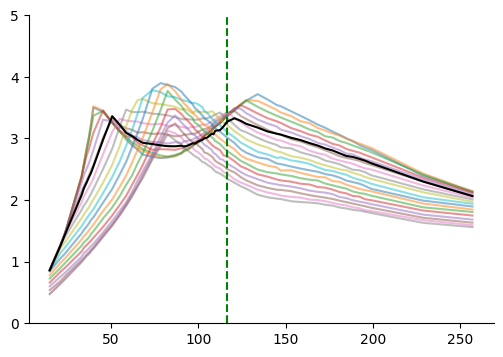

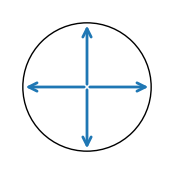

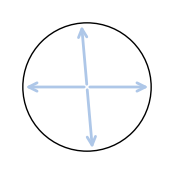

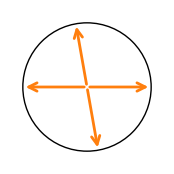

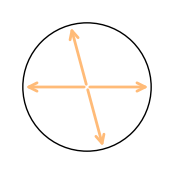

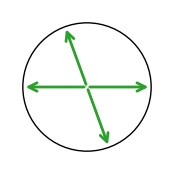

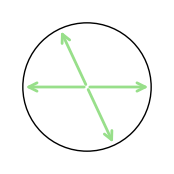

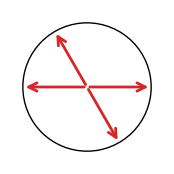

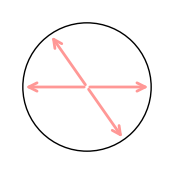

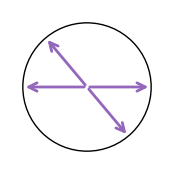

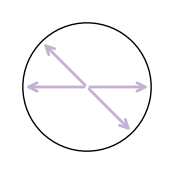

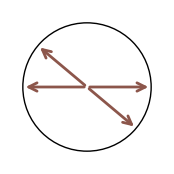

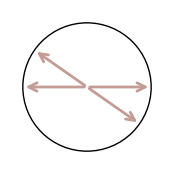

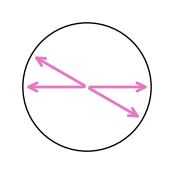

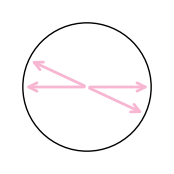

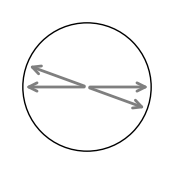

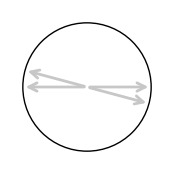

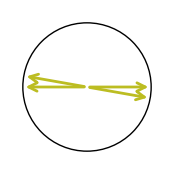

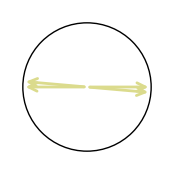

In [232]:
print(prll_ssis.shape)
print(mu_shift)
plt.figure(figsize = (6,4))
plt.plot(data_dict['all_quad_fwhm'][example].mean(axis=1), prll_ssis.min(axis=2).T, alpha = 0.5)

plt.axvline(data_dict['all_quad_fwhm'][example,bio_idx].mean(), color = 'green', ls='dashed')

plt.plot(data_dict['all_quad_fwhm'][example].mean(axis=1), data_dict['all_ssis'][example].min(axis=1),\
        color = 'k')
plt.ylim(0,5)

# default matplotlib color cycle
colors = plt.get_cmap('tab20').colors

for angles, c in zip(prll_shifted_pars_het[:,bio_idx, :,1], colors):  # degrees
    print(angles)
    fig, ax = plt.subplots(figsize=(2,2))

    # circle
    circle = plt.Circle((0,0), 1, fill=False)
    ax.add_patch(circle)

    # arrows
    for a in np.deg2rad(angles):
        x, y = np.cos(a), np.sin(a)

        arrow = FancyArrowPatch(
            (0,0), (x,y),
            arrowstyle='->',
            mutation_scale=15,
            linewidth=2,
            color=c,
            fill=False   # makes the head open ("V")
        )
        ax.add_patch(arrow)

    ax.set_aspect('equal')
    ax.set_xlim(-1.2,1.2)
    ax.set_ylim(-1.2,1.2)
    ax.axis('off')

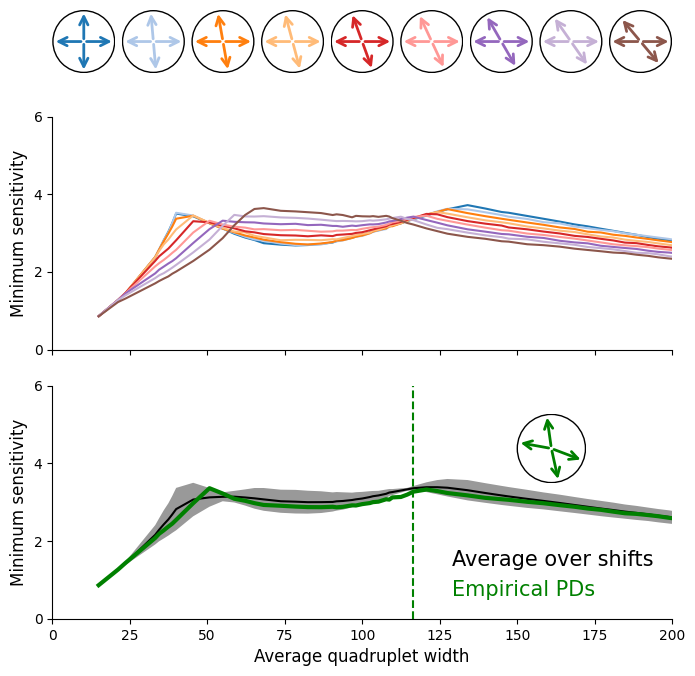

In [165]:
example = 201
data=np.load(output_dir+'prll_ssi.npz')
mu_shift = data['mu_shift']
prll_shifted_pars_het = data['prll_shifted_pars_het']
prll_ssis = data['prll_ssis']


# --- Settings ---
# Get the tab10 colors
all_colors = plt.get_cmap('tab20').colors  # tuple of 10 RGB colors
# The green color in tab10 is at index 1
colors = tuple(c for i, c in enumerate(all_colors) if i not in [4,5])


n_arrows = np.count_nonzero(mu_shift<45)  # total arrow plots
angles_array = prll_shifted_pars_het[mu_shift<45, bio_idx, :, 1]  # shape (18, 4)

fig = plt.figure(figsize=(8, 8))
gs = GridSpec(3, 9, figure=fig, height_ratios=[1, 3, 3], hspace=0.2, wspace=0.1)

# --- Top 2 rows: arrow plots ---
for i in range(n_arrows):
    row = i // 9
    col = i % 9
    ax = fig.add_subplot(gs[row, col])

    ax.add_patch(plt.Circle((0,0), 1, fill=False, lw=1))

    for a in np.deg2rad(angles_array[i]):
        x, y = np.cos(a), np.sin(a)
        arrow = FancyArrowPatch(
            (0,0), (x,y),
            arrowstyle='->',
            mutation_scale=15,
            linewidth=2,
            color=colors[i],
            fill=False
        )
        ax.add_patch(arrow)

    ax.set_aspect('equal')
    ax.set_xlim(-1.025, 1.025)
    ax.set_ylim(-1.025, 1.025)
    ax.axis('off')

    
ax0 = fig.add_subplot(gs[1, :])
for i in range(n_arrows):
    ax0.plot(data_dict['all_quad_fwhm'][example].mean(axis=1), prll_ssis[i].min(axis=1), 
            color=colors[i])

ax0.set_ylim(0, 6)
ax0.set_yticks(np.arange(0,6.1,2))
ax0.set_xlim(0,200)
ax0.set_ylabel('Minimum sensitivity', size = 12)
ax0.set_xticklabels([])
# --- Bottom row: prll_ssis lines ---
ax = fig.add_subplot(gs[2, :])


ax.plot(data_dict['all_quad_fwhm'][example].mean(axis=1), prll_ssis[mu_shift<45].min(axis=2).mean(axis=0), 
        color='black', label = 'Average over shifts')

ax.fill_between(data_dict['all_quad_fwhm'][example].mean(axis=1), \
                prll_ssis[mu_shift<45].min(axis=2).mean(axis=0)-prll_ssis[mu_shift<45].min(axis=2).std(axis=0),\
                prll_ssis[mu_shift<45].min(axis=2).mean(axis=0)+prll_ssis[mu_shift<45].min(axis=2).std(axis=0),
        color='black', alpha = 0.4, edgecolor = None)

    
# Optional: overlay other reference lines
ax.axvline(data_dict['all_quad_fwhm'][example, bio_idx].mean(), color='green', ls='dashed')
ax.plot(data_dict['all_quad_fwhm'][example].mean(axis=1), 
        data_dict['all_ssis'][example].min(axis=1), color='green', lw=3, label = 'Empirical PDs')

ax.set_ylim(0, 6)
ax.set_yticks(np.arange(0,6.1,2))
ax.set_xlim(0,200)
ax.set_xlabel('Average quadruplet width', size =12)
ax.set_ylabel('Minimum sensitivity', size = 12)
ax.legend(handlelength = 0, labelcolor = 'linecolor', frameon=0, fontsize = 15, loc = 'lower right')
# --- Add inset in the bottom prll_ssis plot ---
# ax is the main SSI axes from previous code
axins = inset_axes(ax, width="30%", height="30%", loc='upper right', borderpad=2)

# Circle in inset
axins.add_patch(plt.Circle((0,0), 1, fill=False, lw=1))

# Example 4 green arrows
example_angles = data_dict['all_quad_pars'][example, bio_idx, :,1]  # degrees
for a in np.deg2rad(example_angles):
    x, y = np.cos(a), np.sin(a)
    arrow = FancyArrowPatch(
        (0,0), (x,y),
        arrowstyle='->',
        mutation_scale=15,
        linewidth=2,
        color='green',  # black arrows
        fill=False
    )
    axins.add_patch(arrow)

axins.set_aspect('equal')
axins.set_xlim(-1.025, 1.025)
axins.set_ylim(-1.025, 1.025)
axins.axis('off')

fig.savefig(output_dir+f'Shift_minSSI_quad{example}.jpg', bbox_inches = 'tight', dpi = 300)

In [85]:
mu_shift = np.arange(0,45,5)

homo_pars = np.tile(np.array([600,0, 0.6, 0.01, 25])[None,None,None,:], \
                    (mu_shift.shape[0], data_dict['all_multipliers'].shape[0], 4,1))
homo_pars[:,:,:,1] = np.arange(0,360,90)[None,None,:]
homo_pars[:,:,1,1] += mu_shift[:,None]
homo_pars[:,:,3,1] += mu_shift[:,None]


homo_pars[:,:,:,2] *= data_dict['all_multipliers'][None,:,None]

homo_tcs = np.array([np.array([np.array([ssiMod.FTVM_dx(stim, *pars) for pars in quad_pars]) \
                               for quad_pars in quad_width]) for quad_width in homo_pars])

homo_ssis = np.array([np.array([ssiMod.MC_SSI(quad_tcs) for quad_tcs in tqdm(width)]) for width in tqdm(homo_tcs)])

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

In [103]:
homo_fwhm = np.array([np.array([ssiMod.FWHM(pars)[1] for pars in tc_pars]) for tc_pars in homo_pars[:,:,0,:]])
np.savez(output_dir+'homo_case.npz', mu_shift=mu_shift, \
         homo_pars=homo_pars, homo_tcs=homo_tcs, homo_ssis=homo_ssis)


(9, 56)


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
/home/cparis/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:61: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


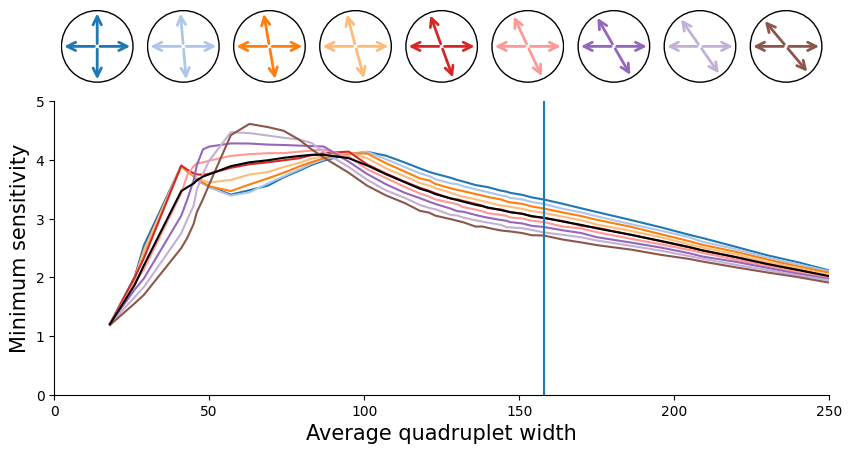

In [127]:


# --- Settings ---
# Get the tab10 colors
all_colors = plt.get_cmap('tab20').colors  # tuple of 10 RGB colors
# The green color in tab10 is at index 1
colors = tuple(c for i, c in enumerate(all_colors) if i not in [4,5])


n_arrows = np.count_nonzero(mu_shift<45)  # total arrow plots
angles_array = homo_pars[mu_shift<45, bio_idx, :, 1]  # shape (18, 4)

fig = plt.figure(figsize=(10, 5))
gs = GridSpec(2, 9, figure=fig, height_ratios=[1, 4], hspace=0.1, wspace=0)

# --- Top 2 rows: arrow plots ---
for i in range(n_arrows):
    row = i // 9
    col = i % 9
    ax = fig.add_subplot(gs[row, col])

    ax.add_patch(plt.Circle((0,0), 1, fill=False, lw=1))

    for a in np.deg2rad(angles_array[i]):
        x, y = np.cos(a), np.sin(a)
        arrow = FancyArrowPatch(
            (0,0), (x,y),
            arrowstyle='->',
            mutation_scale=15,
            linewidth=2,
            color=colors[i],
            fill=False
        )
        ax.add_patch(arrow)

    ax.set_aspect('equal')
    ax.set_xlim(-1.025, 1.025)
    ax.set_ylim(-1.025, 1.025)
    ax.axis('off')

# --- Bottom row: prll_ssis lines ---
ax = fig.add_subplot(gs[1, :])
for i in range(n_arrows):
    ax.plot(homo_fwhm[i], homo_ssis[i].min(axis=1), 
            color=colors[i])
    
#     ax.plot(homo_fwhm[i], homo_ssis[i].mean(axis=1), 
#             color=colors[i])
ax.plot(homo_fwhm[i], homo_ssis.min(axis=2).mean(axis=0), 
        color='k')
    
ax.axvline(ssiMod.FWHM(np.array([600,0, 0.6, 0.01, 25]))[1])
ax.set_ylim(0, 5)
ax.set_xlim(0,250)
ax.set_xlabel('Average quadruplet width', size =15)
ax.set_ylabel('Minimum sensitivity', size = 15)
ax.legend(handlelength = 0, labelcolor = 'linecolor', frameon=0, fontsize = 15, loc = 'lower right')

plt.tight_layout()
plt.show()

In [104]:
example = 125
example_quad_pars_og = data_dict['all_quad_pars'][example]
example_quad_pars_het = np.copy(example_quad_pars_og)       #56x4x5
example_quad_pars_het[:,:,1] = np.tile(np.arange(0,360,90), (example_quad_pars_het.shape[0],1))

mu_shift = np.arange(0, 45, 5)
prll_shifted_pars_het = np.tile(example_quad_pars_het[None,:,:,:], (mu_shift.shape[0], 1,1,1))

prll_shifted_pars_het[:,:,1,1] += mu_shift[:,None]
prll_shifted_pars_het[:,:,3,1] += mu_shift[:,None]

prll_tcs = np.array([np.array([np.array([ssiMod.FTVM_dx(stim, *pars) for pars in quad]) \
                              for quad in width]) for width in prll_shifted_pars_het])

prll_ssis = np.array([np.array([ssiMod.MC_SSI(quad_tc) \
                                    for quad_tc in tqdm(tc_width)]) for tc_width in tqdm(prll_tcs)])

# np.savez(output_dir+f'prll_ssi_quad{example}.npz', mu_shift = mu_shift, \
#         prll_shifted_pars_het=prll_shifted_pars_het, prll_tcs=prll_tcs, prll_ssis=prll_ssis)

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

[40 39 39 38 38 37 36 34 28]


/home/cparis/anaconda3/lib/python3.7/site-packages/scipy/signal/_arraytools.py:45: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  b = a[a_slice]


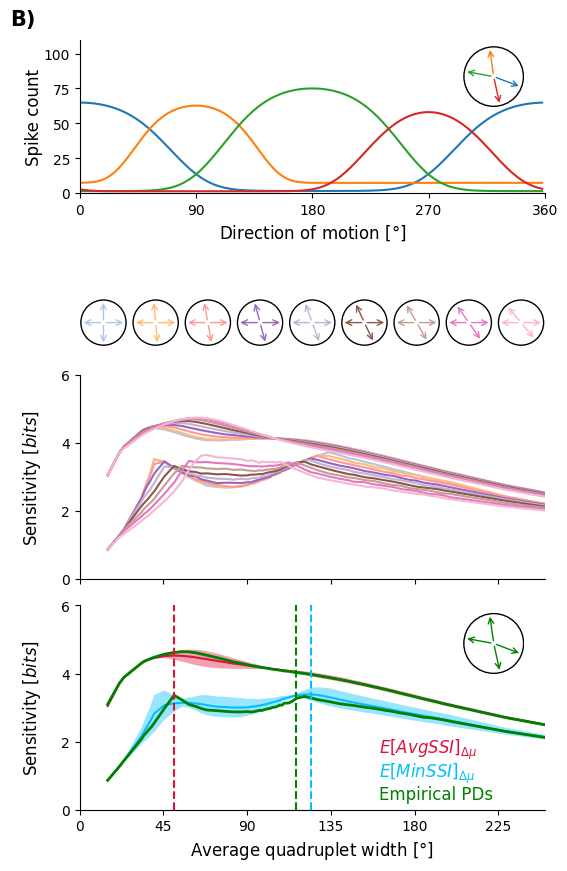

In [6]:
example, panel_text = 125, 'A)'
example, panel_text = 201, 'B)'
data=np.load(output_dir+f'prll_ssi_quad{example}.npz')
mu_shift = data['mu_shift']
prll_shifted_pars_het = data['prll_shifted_pars_het']
prll_ssis = data['prll_ssis']

smoothing_strategy = 2
tolerance = 0

##  SAVITZKY - GOLAY FILTER
ssi_min_filt = np.array([savgol_filter(ssi_evol_raw,3,1) for \
                         ssi_evol_raw in [prll_ssis[mu_shift<45].min(axis=2).mean(axis=0)]])
ssi_avg_filt = np.array([savgol_filter(ssi_evol_raw,3,1) for \
                         ssi_evol_raw in [prll_ssis[mu_shift<45].mean(axis=2).mean(axis=0)]])
    
optima_min = np.array([find_peaks(el[data_dict['all_quad_fwhm'][example,0:len(el)].mean(axis=1)<=150], \
                                        prominence=np.std(el)*tolerance)[0][-1] \
                       for i,el in enumerate(ssi_min_filt)])
optima_avg = np.array([find_peaks(el[data_dict['all_quad_fwhm'][example, 0:len(el)].mean(axis=1)<=150], \
                                        prominence=np.std(el)*tolerance)[0][-1] for i,el in \
                  enumerate(ssi_avg_filt)])

optima_widths_min = np.array([data_dict['all_quad_fwhm'][example, el].mean() for _,el in enumerate(optima_min)])
optima_widths_avg = np.array([data_dict['all_quad_fwhm'][example, el].mean() for _,el in enumerate(optima_avg)])

# --- Settings ---
# Get the tab10 colors
all_colors = plt.get_cmap('tab20').colors  # tuple of 10 RGB colors
# The green color in tab10 is at index 1
colors = tuple(c for i, c in enumerate(all_colors) if i not in [0,2,4,5,6])


n_arrows = np.count_nonzero(mu_shift<45)  # total arrow plots
angles_array = prll_shifted_pars_het[mu_shift<45, bio_idx, :, 1]  # shape (18, 4)

fig = plt.figure(figsize=(6, 10))
gs = GridSpec(5, 9, figure=fig, height_ratios=[3, 1,1, 4, 4], hspace=0.2, wspace=0.1)

tc_quad = np.array([ssiMod.FTVM_dx(stim, *pars) for pars in prll_shifted_pars_het[0,bio_idx]])
ymax = (max(tc_quad.flatten())*1.5)//10*10
ax_quad = fig.add_subplot(gs[0, :])
lines = ax_quad.plot(stim, tc_quad.T)
example_angles = data_dict['all_quad_pars'][example, bio_idx, :,1]  # degrees

# --- Add inset in the bottom prll_ssis plot ---
# ax is the main SSI axes from previous code
axins = inset_axes(ax_quad, width="40%", height="40%", loc='upper right',
        bbox_to_anchor=(0.12, 0.05, 1, 1), bbox_transform = ax_quad.transAxes, borderpad=1)

# Circle in inset
axins.add_patch(plt.Circle((0,0), 1, fill=False, lw=1))

for i,a in enumerate(np.deg2rad(example_angles)):
    x, y = np.cos(a), np.sin(a)
    arrow = FancyArrowPatch(
        (0,0), (x,y),
        arrowstyle='->',
        mutation_scale=10,
        linewidth=1,
        color= lines[i].get_color(),  # black arrows
        fill=False
    )
    axins.add_patch(arrow)

axins.set_aspect('equal')
axins.set_xlim(-1.03, 1.03)
axins.set_ylim(-1.03, 1.03)
axins.axis('off')

ax_quad.set_xticks(np.arange(0,361,90))
ax_quad.set_yticks(np.arange(0,ymax+1,25))
ax_quad.set_xlim(0,360)
ax_quad.set_ylim(0,ymax)
ax_quad.set_xlabel('Direction of motion [$\degree$]', size = 12)
ax_quad.set_ylabel('Spike count', size = 12)
ax_quad.yaxis.set_label_coords(-0.08, 0.5)
ax_quad.text(-0.15, 1.2, panel_text, ha='left', va='top', transform=ax_quad.transAxes, \
             fontweight='bold', fontsize = 15)


# --- Top 2 rows: arrow plots ---
for i in range(n_arrows):
    row = i // 9 + 2
    col = i % 9
    ax = fig.add_subplot(gs[row, col])

    ax.add_patch(plt.Circle((0,0), 1, fill=False, lw=1))

    for a in np.deg2rad(angles_array[i]):
        x, y = np.cos(a), np.sin(a)
        arrow = FancyArrowPatch(
            (0,0), (x,y),
            arrowstyle='->',
            mutation_scale=10,
            linewidth=1,
            color=colors[i],
            fill=False
        )
        ax.add_patch(arrow)

    ax.set_aspect('equal')
    ax.set_xlim(-1.05, 1.05)
    ax.set_ylim(-1.05, 1.05)
    ax.axis('off')

    
ax0 = fig.add_subplot(gs[3, :])
for i in range(n_arrows):
    ax0.plot(data_dict['all_quad_fwhm'][example].mean(axis=1), prll_ssis[i].min(axis=1), 
            color=colors[i])
    
    ax0.plot(data_dict['all_quad_fwhm'][example].mean(axis=1), prll_ssis[i].mean(axis=1), 
            color=colors[i])

#     ax0.axvline(optima_widths_min[i], color=colors[i])

    xmax = (data_dict['all_quad_fwhm'][example].mean(axis=1)[-1]//10)*10
ax0.set_ylim(0, 6)
ax0.set_yticks(np.arange(0,6.1,2))
ax0.set_ylabel(r'Sensitivity [$bits$]', size = 12)
ax0.set_xticks(np.arange(0,271,45))
ax0.set_xlim(0,xmax)
ax0.set_xticklabels([])
ax0.yaxis.set_label_coords(-0.08, 0.5)


# --- Bottom row: prll_ssis lines ---
ax = fig.add_subplot(gs[4, :])



ax.plot(data_dict['all_quad_fwhm'][example].mean(axis=1), prll_ssis[mu_shift<45].mean(axis=2).mean(axis=0), 
        color='Crimson', label = r'$E[AvgSSI]_{\Delta\mu}$')

ax.fill_between(data_dict['all_quad_fwhm'][example].mean(axis=1), \
                prll_ssis[mu_shift<45].mean(axis=2).mean(axis=0)-prll_ssis[mu_shift<45].mean(axis=2).std(axis=0),\
                prll_ssis[mu_shift<45].mean(axis=2).mean(axis=0)+prll_ssis[mu_shift<45].mean(axis=2).std(axis=0),
        color='Crimson', alpha = 0.4, edgecolor = None)

ax.plot(data_dict['all_quad_fwhm'][example].mean(axis=1), prll_ssis[mu_shift<45].min(axis=2).mean(axis=0), 
        color='deepskyblue', label = r'$E[MinSSI]_{\Delta\mu}$')

ax.fill_between(data_dict['all_quad_fwhm'][example].mean(axis=1), \
                prll_ssis[mu_shift<45].min(axis=2).mean(axis=0)-prll_ssis[mu_shift<45].min(axis=2).std(axis=0),\
                prll_ssis[mu_shift<45].min(axis=2).mean(axis=0)+prll_ssis[mu_shift<45].min(axis=2).std(axis=0),
        color='deepskyblue', alpha = 0.4, edgecolor = None)
    
# Optional: overlay other reference lines
ax.axvline(data_dict['all_quad_fwhm'][example, bio_idx].mean(), color='green', ls='dashed')

ax.plot(data_dict['all_quad_fwhm'][example].mean(axis=1), 
        data_dict['all_ssis'][example].min(axis=1), color='green', lw=2, label = 'Empirical PDs')
ax.plot(data_dict['all_quad_fwhm'][example].mean(axis=1), 
        data_dict['all_ssis'][example].mean(axis=1), color='green', lw=2)

ax.axvline(optima_widths_min.mean(), color='deepskyblue', ls = 'dashed')
ax.axvline(optima_widths_avg.mean(), color='crimson', ls = 'dashed')

# print(optima_widths_min,optima_widths_min.mean())



xmax = (data_dict['all_quad_fwhm'][example].mean(axis=1)[-1]//10)*10

ax.set_ylim(0, 6)
ax.set_yticks(np.arange(0,6.1,2))
ax.set_xticks(np.arange(0,271,45))
ax.set_xlim(0,xmax)
ax.set_xlabel(r'Average quadruplet width [$\degree$]', size =12)
ax.set_ylabel(r'Sensitivity [$bits$]', size = 12)
ax.yaxis.set_label_coords(-0.08, 0.5)


ax.legend(handlelength = 0, labelcolor = 'linecolor', frameon=0, fontsize = 12, loc = (0.6, 0.),\
         labelspacing = 0.)
# --- Add inset in the bottom prll_ssis plot ---
# ax is the main SSI axes from previous code
axins = inset_axes(ax, width="30%", height="30%", loc='upper right', \
                   bbox_to_anchor = (0.1,0.1,1,1), bbox_transform = ax.transAxes, borderpad=2)

# Circle in inset
axins.add_patch(plt.Circle((0,0), 1, fill=False, lw=1))

# Example 4 green arrows
example_angles = data_dict['all_quad_pars'][example, bio_idx, :,1]  # degrees
for a in np.deg2rad(example_angles):
    x, y = np.cos(a), np.sin(a)
    arrow = FancyArrowPatch(
        (0,0), (x,y),
        arrowstyle='->',
        mutation_scale=10,
        linewidth=1,
        color='green',  # black arrows
        fill=False
    )
    axins.add_patch(arrow)

axins.set_aspect('equal')
axins.set_xlim(-1.025, 1.025)
axins.set_ylim(-1.025, 1.025)
axins.axis('off')

fig.savefig(output_dir+f'Shift_minSSI_quad{example}.jpg', bbox_inches = 'tight', dpi = 300)

In [7]:
example = 201
data=np.load(output_dir+f'prll_ssi.npz')
mu_shift = data['mu_shift']
prll_shifted_pars_het = data['prll_shifted_pars_het']
prll_ssis = data['prll_ssis']


# --- Settings ---
# Get the tab10 colors
all_colors = plt.get_cmap('tab20').colors  # tuple of 10 RGB colors
# The green color in tab10 is at index 1
colors = tuple(c for i, c in enumerate(all_colors) if i not in [0,2,4,5,6])


n_arrows = np.count_nonzero(mu_shift<45)  # total arrow plots
angles_array = prll_shifted_pars_het[mu_shift<45, bio_idx, :, 1]  # shape (18, 4)

fig = plt.figure(figsize=(6, 10))
gs = GridSpec(5, 9, figure=fig, height_ratios=[3, 1,1, 4, 4], hspace=0.2, wspace=0.1)

ax_quad = fig.add_subplot(gs[0, :])
lines = ax_quad.plot(stim, np.array([ssiMod.FTVM_dx(stim, *pars) for pars in prll_shifted_pars_het[0,bio_idx]]).T)
example_angles = data_dict['all_quad_pars'][example, bio_idx, :,1]  # degrees

# --- Add inset in the bottom prll_ssis plot ---
# ax is the main SSI axes from previous code
axins = inset_axes(ax_quad, width="35%", height="35%", loc='upper right',
        bbox_to_anchor=(0.075, 0.15, 1, 1), bbox_transform = ax_quad.transAxes, borderpad=2)

# Circle in inset
axins.add_patch(plt.Circle((0,0), 1, fill=False, lw=1))

for i,a in enumerate(np.deg2rad(example_angles)):
    x, y = np.cos(a), np.sin(a)
    arrow = FancyArrowPatch(
        (0,0), (x,y),
        arrowstyle='->',
        mutation_scale=10,
        linewidth=1,
        color= lines[i].get_color(),  # black arrows
        fill=False
    )
    axins.add_patch(arrow)

axins.set_aspect('equal')
axins.set_xlim(-1.03, 1.03)
axins.set_ylim(-1.03, 1.03)
axins.axis('off')

ax_quad.set_xticks(np.arange(0,361,90))
ax_quad.set_yticks(np.arange(0,101,20))
ax_quad.set_xlim(0,360)
ax_quad.set_ylim(0,100)
ax_quad.set_xlabel('Direction of motion [$\degree$]', size = 12)
ax_quad.set_ylabel('Spike count', size = 12)


# --- Top 2 rows: arrow plots ---
for i in range(n_arrows):
    row = i // 9 + 2
    col = i % 9
    ax = fig.add_subplot(gs[row, col])

    ax.add_patch(plt.Circle((0,0), 1, fill=False, lw=1))

    for a in np.deg2rad(angles_array[i]):
        x, y = np.cos(a), np.sin(a)
        arrow = FancyArrowPatch(
            (0,0), (x,y),
            arrowstyle='->',
            mutation_scale=10,
            linewidth=1,
            color=colors[i],
            fill=False
        )
        ax.add_patch(arrow)

    ax.set_aspect('equal')
    ax.set_xlim(-1.025, 1.025)
    ax.set_ylim(-1.025, 1.025)
    ax.axis('off')

    
ax0 = fig.add_subplot(gs[3, :])
for i in range(n_arrows):
    ax0.plot(data_dict['all_quad_fwhm'][example].mean(axis=1), prll_ssis[i].min(axis=1), 
            color=colors[i])
    
    ax0.plot(data_dict['all_quad_fwhm'][example].mean(axis=1), prll_ssis[i].mean(axis=1), 
            color=colors[i])

ax0.set_ylim(0, 6)
ax0.set_yticks(np.arange(0,6.1,2))
ax0.set_xlim(0,220)
ax0.set_ylabel('Minimum sensitivity', size = 12)
ax0.set_xticks(np.arange(0,226,45))
ax0.set_xticklabels([])
# --- Bottom row: prll_ssis lines ---
ax = fig.add_subplot(gs[4, :])



ax.plot(data_dict['all_quad_fwhm'][example].mean(axis=1), prll_ssis[mu_shift<45].mean(axis=2).mean(axis=0), 
        color='Crimson', label = r'$E[AvgSSI]_{\Delta\mu}$')

ax.fill_between(data_dict['all_quad_fwhm'][example].mean(axis=1), \
                prll_ssis[mu_shift<45].mean(axis=2).mean(axis=0)-prll_ssis[mu_shift<45].mean(axis=2).std(axis=0),\
                prll_ssis[mu_shift<45].mean(axis=2).mean(axis=0)+prll_ssis[mu_shift<45].mean(axis=2).std(axis=0),
        color='Crimson', alpha = 0.4, edgecolor = None)

ax.plot(data_dict['all_quad_fwhm'][example].mean(axis=1), prll_ssis[mu_shift<45].min(axis=2).mean(axis=0), 
        color='deepskyblue', label = r'$E[MinSSI]_{\Delta\mu}$')

ax.fill_between(data_dict['all_quad_fwhm'][example].mean(axis=1), \
                prll_ssis[mu_shift<45].min(axis=2).mean(axis=0)-prll_ssis[mu_shift<45].min(axis=2).std(axis=0),\
                prll_ssis[mu_shift<45].min(axis=2).mean(axis=0)+prll_ssis[mu_shift<45].min(axis=2).std(axis=0),
        color='deepskyblue', alpha = 0.4, edgecolor = None)
    
# Optional: overlay other reference lines
ax.axvline(data_dict['all_quad_fwhm'][example, bio_idx].mean(), color='green', ls='dashed')
ax.plot(data_dict['all_quad_fwhm'][example].mean(axis=1), 
        data_dict['all_ssis'][example].min(axis=1), color='green', lw=3, label = 'Empirical PDs')

ax.set_ylim(0, 6)
ax.set_yticks(np.arange(0,6.1,2))
ax.set_xlim(0,220)
ax.set_xticks(np.arange(0,226,45))
ax.set_xlabel('Average quadruplet width', size =12)
ax.set_ylabel('Minimum sensitivity', size = 12)
ax.legend(handlelength = 0, labelcolor = 'linecolor', frameon=0, fontsize = 12, loc = (0.6, 0.),\
         labelspacing = 0.)
# --- Add inset in the bottom prll_ssis plot ---
# ax is the main SSI axes from previous code
axins = inset_axes(ax, width="30%", height="30%", loc='upper right', \
                   bbox_to_anchor = (0.1,0.05,1,1), bbox_transform = ax.transAxes, borderpad=2)

# Circle in inset
axins.add_patch(plt.Circle((0,0), 1, fill=False, lw=1))

# Example 4 green arrows
example_angles = data_dict['all_quad_pars'][example, bio_idx, :,1]  # degrees
for a in np.deg2rad(example_angles):
    x, y = np.cos(a), np.sin(a)
    arrow = FancyArrowPatch(
        (0,0), (x,y),
        arrowstyle='->',
        mutation_scale=10,
        linewidth=1,
        color='green',  # black arrows
        fill=False
    )
    axins.add_patch(arrow)

axins.set_aspect('equal')
axins.set_xlim(-1.025, 1.025)
axins.set_ylim(-1.025, 1.025)
axins.axis('off')

# fig.savefig(output_dir+f'Shift_minSSI_quad{example}.jpg', bbox_inches = 'tight', dpi = 300)

FileNotFoundError: [Errno 2] No such file or directory: '/home/cparis/00PhD/DS_PCBreview/prll_ssi.npz'

/home/cparis/anaconda3/lib/python3.7/site-packages/scipy/signal/_arraytools.py:45: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  b = a[a_slice]


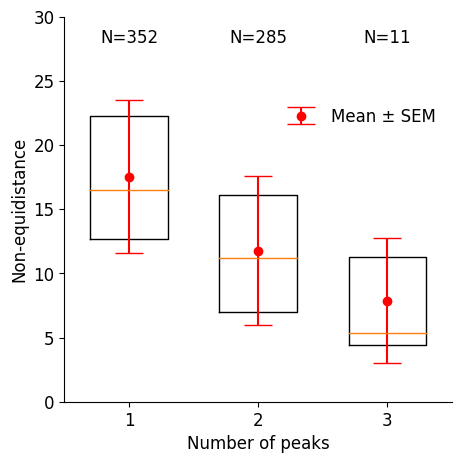

In [12]:
from collections import Counter
from scipy.stats import circmean

og_mus = data_dict['all_quad_pars'][:,bio_idx,:,1]
homo_pds = np.roll(np.arange(0,360,90)[None,:],0) + og_mus[:,0][:,None]
pd_diffs = np.sqrt(np.mean((180-np.abs(180 - np.abs(homo_pds-og_mus)))**2, axis=1))

peaks_min = [find_peaks(savgol_filter(quad_ssi.min(axis=1), \
                                      window_length=3, \
                                      polyorder=0)[np.where(data_dict['all_quad_fwhm'].mean(axis=2)[i]<=180)], \
                        distance = 5, prominence=0.05)[0] for i,quad_ssi in enumerate(data_dict['all_ssis'])]

print


peaks_num = np.array([len(peaks_min[i]) for i in range(len(peaks_min))])


fig, ax = plt.subplots(figsize = (5,5))

cond1, cond2,cond3 = pd_diffs[peaks_num==1], pd_diffs[peaks_num==2], pd_diffs[peaks_num==3]


# Boxplot
ax.boxplot([cond1, cond2, cond3], positions=[1, 2, 3], widths=0.6, showfliers=True,     \
           whiskerprops=dict(linewidth=0),capprops=dict(linewidth=0))

for i,el in enumerate([cond1, cond2, cond3]):
    ax.text(i+1, 28, f'N={len(el)}', size = 12, ha='center')

# Means
means = np.array([cond1.mean(), cond2.mean(), cond3.mean()])

# Errorbars (SEM here)
errors = np.array([cond1.std(), cond2.std(), cond3.std()])


ax.errorbar(
    [1, 2, 3], means,
    yerr=errors,
    fmt='o',
    color='red',
    capsize=10,
    label='Mean ± SEM'
)

ax.set_xticks([1, 2, 3], size = 12)
ax.set_xticklabels(['1', '2', '3'], size = 12)
ax.set_xlabel('Number of peaks', size =12)

ax.set_ylabel(f'Non-equidistance', size = 12)
ax.set_yticks(np.arange(0,31,5), size=12)
ax.set_yticklabels(np.arange(0,31,5), size=12)
ax.set_ylim(0,30)
ax.legend(frameon=0, fontsize = 12, loc = (0.55, 0.7))

fig.savefig(output_dir+'Non_eqdis_vs_num_peaks.jpg', bbox_inches = 'tight', dpi = 300)


In [11]:
stat, p = ks_2samp(cond3, cond2)

print(stat, p)

0.4574162679425837 0.015488659549255457


[  0  90 180 270]
[  0.          90.90227709 180.         270.90227709]
[  0.          93.69522053 180.         273.69522053]
[  0.          98.65012087 180.         278.65012087]
[  0.         106.26020471 180.         286.26020471]
[  0.         117.28582955 180.         297.28582955]
[  0.         132.74124454 180.         312.74124454]
[  0.         153.61877858 180.         333.61877858]
[[  0.          90.         180.         270.        ]
 [359.54886145  90.45113855 179.54886145 270.45113855]
 [358.15238973  91.84761027 178.15238973 271.84761027]
 [355.67493957  94.32506043 175.67493957 274.32506043]
 [351.86989765  98.13010235 171.86989765 278.13010235]
 [346.35708522 103.64291478 166.35708522 283.64291478]
 [338.62937773 111.37062227 158.62937773 291.37062227]
 [328.19061071 121.80938929 148.19061071 301.80938929]]


/home/cparis/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:168: RuntimeWarning: invalid value encountered in double_scalars
/home/cparis/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:282: RuntimeWarning: invalid value encountered in remainder


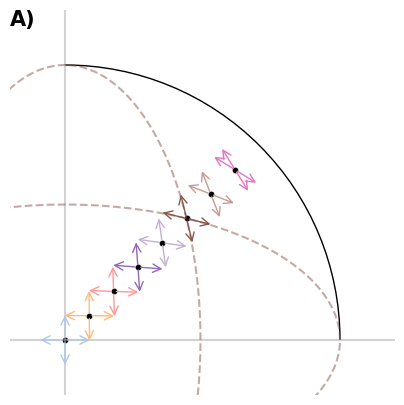

In [241]:
import numpy as np
import matplotlib.pyplot as plt
plt.close()
import matplotlib as mpl
from matplotlib import gridspec

from brokenaxes import brokenaxes

mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False
import os
import pickle5 as pickle
import csv
from scipy.optimize import curve_fit
from scipy.signal import savgol_filter

import import_ipynb
import ipynb.fs.full.ssiProjectModule2 as ssiMod

from tqdm.notebook import tqdm
import sys

import importlib as imp
imp.reload(ssiMod)

from scipy.stats import wilcoxon as w
from scipy.special import factorial
from scipy.stats import circmean
from scipy.stats import circstd
import math
import statsmodels.stats.api as sms

from multiprocessing import Pool
from functools import partial

from mpl_toolkits.axes_grid1.inset_locator import inset_axes

from datetime import datetime
import bisect


main_dir = '/home/cparis/00PhD/DS_PCBreview/'

from matplotlib.patches import Arc,FancyArrowPatch

def plot_circle(ax, angle_deg, R=1.0):

    theta = np.deg2rad(angle_deg)

    x = R * np.cos(theta)
    y = R * np.sin(theta)

    # Draw only first quadrant arc
    arc = Arc((0, 0), 2*R, 2*R, theta1=0, theta2=90)
    ax.add_patch(arc)

    # Formatting
    ax.set_aspect('equal', adjustable='datalim')

    # restrict axes to first quadrant
    ax.set_xlim(-0.2*R, 1.2*R)
    ax.set_ylim(-0.2*R, 1.2*R)

    ax.axhline(0, alpha=0.5, c='darkgrey')
    ax.axvline(0, alpha=0.5, c='darkgrey')

    ax.grid(False)
    ax.axis('off')

def draw_arrow(ax, x0, y0, theta, length,
               color='k', lw=1, scale=15, style='->', open_head=True):
    
    x1 = x0 + length*np.cos(theta)
    y1 = y0 + length*np.sin(theta)

    arrow = FancyArrowPatch(
        (x0, y0),
        (x1, y1),
        arrowstyle=style,
        mutation_scale=scale,
        linewidth=lw,
        color=color,
        fill=not open_head,
        zorder = 5
    )

    ax.add_patch(arrow)

def draw_ellipse(ax, a, b, color='grey'):
    # Parameter t
    t = np.linspace(0, 2*np.pi, 400)
    
    # Ellipse parametric equations
    x = a * np.cos(t)
    y = b * np.sin(t)
    
    # Plot
#     plt.figure()
    plt.plot(x, y, linestyle='dashed', color=color, alpha = 0.5)
    plt.gca().set_aspect('equal', adjustable='box')
    
    # Axes and grid
#     plt.title(f"Ellipse with radii a={a}, b={np.around(b,2)}")

def complex_from_polar(k, theta):
    return k * np.exp(1j * np.deg2rad(theta))

def flow_ellipse_axis(x,y, Ry=1):
#     returns the minor ellipse axis along the x axis
    if y==Ry:
        return Ry/2  #arbitrary value
    else:
        return x/np.sqrt(1.-(y/Ry)**2)

def ellipse_slope_in_xy(x,y,Rx,Ry):
    if Rx==0:
        return -np.inf*np.sign(y)  #case where ellipse is collapsed onto a segment [-Ry, Ry]
    elif y==0:
        return -np.sign(x)*np.inf
    else:
        return -(x/y)*(Ry/Rx)**2 


def flow_in_point_of_ellipse_horizontal(x,z, x_ax, z_ax, arrow_len, hor_comp_th):
#     NOTE: MODIFICATION OF LENGTH:
#           Consider 2 arrows at same source point, one pointing towards a pole, other pointing away from it
#           The arrow pointing towards will appear shorter when projected because of sphere curvature
#           This is coded in "np.sign(phi*x)*delta_arc" term

    slope_h = ellipse_slope_in_xy(x,z, a_ax, z_ax)
    if np.abs(slope_h)!=np.inf:
        mod_dir_h = np.arctan(slope_h)+(1-np.sign(hor_comp_th))*np.pi/2*np.abs(np.sign(hor_comp_th))
    else: mod_dir_h = np.pi/2 - np.pi/2*np.sign(hor_comp_th)
    lmbda = np.arctan(z/x) if x!=0 else 0.
    phi = np.arccos(np.sqrt(x**2+z**2)/R)
    hor_flow_amp =  np.abs(arrow_len)*np.sqrt(1-np.cos(phi-np.sign(hor_comp_th*x)*delta_arc)**2*np.cos(lmbda)**2)
    print(mod_dir_h)
    return mod_dir_h, hor_flow_amp

def optic_flow_mod(theta, x0, z0):
    # horizontal and vertical components of stimulus direction 
    #(along naso-temporal and dorso-ventral axes, respectively)
    hor_comp_th,vert_comp_th = np.cos(theta), np.sin(theta)
    hor_arrow_len, vert_arrow_len = 0.2*hor_comp_th, 0.2*vert_comp_th

    # Naso-temporal flow ellipse - along x axis (ah=1)
    hor_a, hor_b = 1, flow_ellipse_axis(z0,x0)
    vert_b, vert_a = 1, flow_ellipse_axis(x0,z0)
    
    for x in [x0]:
        z = hor_b*np.sqrt(1.-(x/hor_a)**2)
        th1, l1 = flow_in_point_of_ellipse_horizontal(x,z, hor_a, hor_b, hor_arrow_len, hor_comp_th)
    for z in [z0]:
        x = vert_a*np.sqrt(1.-(z/vert_b)**2)
        th2, l2 = flow_in_point_of_ellipse_vertical(x,z, vert_a, vert_b, vert_arrow_len, vert_comp_th)
    final = l1*np.exp(1j*th1) + l2*np.exp(1j*th2)
    return np.sqrt(final.real**2+final.imag**2), np.rad2deg(np.angle(final))%360

def flow_ellipse_axis(x,y, Ry=1):
#     returns the minor ellipse axis along the x axis
    if y==Ry:
        return Ry/2  #arbitrary value
    else:
        return x/np.sqrt(1.-(y/Ry)**2)

def ellipse_slope_in_xy(x,y,Rx,Ry):
    if Rx==0:
        return -np.inf*np.sign(y)  #case where ellipse is collapsed onto a segment [-Ry, Ry]
    elif y==0:
        return -np.sign(x)*np.inf
    else:
        return -(x/y)*(Ry/Rx)**2 


def flow_in_point_of_ellipse(x,z, x_ax, z_ax, flow_parallel_comp, which, delta_arc = np.deg2rad(15)):
#     NOTE: MODIFICATION OF LENGTH:
#           Consider 2 arrows at same source point, one pointing towards a pole, other pointing away from it
#           The arrow pointing towards will appear shorter when projected because of sphere curvature
#           This is coded in "np.sign(phi*x)*delta_arc" term
    lmbda = np.arctan(z/x) if x!=0 else -np.sign(z)*np.pi
    phi = np.arccos(np.sqrt(x**2+z**2)/R)
    slope_h = ellipse_slope_in_xy(x,z, x_ax, z_ax)
    if np.abs(slope_h)!=np.inf:
        new_theta = np.arctan(slope_h)+(1+np.sign(flow_parallel_comp*x*z))*np.pi/2*np.abs(np.sign(flow_parallel_comp))
        if which=='h':
            new_theta = -new_theta+np.pi/2
    elif np.abs(slope_h)==np.inf and which=='h': 
        new_theta = np.pi/2 - np.pi/2*np.sign(flow_parallel_comp)
#         new_theta = np.pi/2*np.sign(flow_parallel_comp)

    elif np.abs(slope_h)==np.inf and which=='v': 
        new_theta = np.pi/2*np.sign(flow_parallel_comp)
        
    amplitude_mod = np.sqrt(1.-np.cos(phi-np.sign(flow_parallel_comp*z)*delta_arc)**2\
                            *np.sin(lmbda+np.sign(flow_parallel_comp*x)*delta_arc)**2) 

#     if which=='v':
#         amplitude_mod = np.sqrt(1-np.cos(phi-np.sign(flow_parallel_comp*z)*delta_arc)**2*np.cos(lmbda)**2)        
#     elif which=='h':
#         amplitude_mod = np.sqrt(1-np.cos(phi-np.sign(flow_parallel_comp*z)*delta_arc)**2*np.cos(lmbda)**2) 
    return np.abs(flow_parallel_comp)*amplitude_mod, np.rad2deg(new_theta)


def FTVM_dx(th, a, th_0, s, baseline, g):           #indexed with 'ftvm'
    '''Modified Von Mises function\n Parameters Area, mean, concentration, baseline, flatness\n g = 0 gives Von Mises function'''
    '''This version computes the FTVM on a non-uniform dx support, preserving the area under the curve'''
#     get average bins size centered in th[i]: dx[i] = (x[i+1]-x[i-1])/2
    delta_th = (180-np.abs(180-np.abs((np.roll(th, -1) - np.roll(th, 1)))))/2  
#     print(delta_th)
#     get ftvm function value at th[i]
    ftvm_f = np.exp(np.float64((np.cos(np.deg2rad(th-th_0-g*np.sin(np.deg2rad(th-th_0))))-1)/s))
    
    res = (a*ftvm_f/ np.sum(ftvm_f*delta_th/(360/36)) + baseline) 
    return res+np.any(res<0.)*1e10


def direction_deformation(vector, x0,z0, R=1, arrow_len=0.15):
    vert_b, vert_a = R, flow_ellipse_axis(x0,z0)
    hor_a, hor_b = R, flow_ellipse_axis(z0,x0)
    
    for theta in np.deg2rad(vector):
        # upward arrow at (0,0)
        ax.arrow(0, 0, arrow_len*np.cos(theta),arrow_len*np.sin(theta), 
             head_width=arrow_len/5, head_length=arrow_len/3, fc='k', ec='k')
        l_mod_z, th_mod_z = flow_in_point_of_ellipse(x0,z0, vert_a, vert_b, arrow_len*np.sin(theta), 'v')
        l_mod_x, th_mod_x = flow_in_point_of_ellipse(z0,x0, hor_b, hor_a, arrow_len*np.cos(theta), 'h')

        resultant = l_mod_x*np.exp(1j*np.deg2rad(th_mod_x)) + l_mod_z*np.exp(1j*np.deg2rad(th_mod_z))
        final_arr = np.append(final_arr, resultant)

    final_l, final_th = np.sqrt(final_arr.real**2+final_arr.imag**2), np.rad2deg(np.angle(final_arr))%360 

#     print(final_th.shape)
    new_vector = final_l*np.exp(1j*np.deg2rad(final_th))
    return final_l, final_th, new_vector

# Get the tab10 colors
all_colors = plt.get_cmap('tab20').colors  # tuple of 10 RGB colors
# The green color in tab10 is at index 1
colors = tuple(c for i, c in enumerate(all_colors) if i not in [0,2,4,5,6])


R=1

mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False
mpl.rcParams['axes.spines.left'] = False
mpl.rcParams['axes.spines.bottom'] = False
# circle and vertical ellipse

fig, ax = plt.subplots(figsize=(5, 5))

plot_circle(ax, 90, 1)

sabbah = np.array([])

for g, x0 in enumerate(np.linspace(0, R/np.sqrt(2),9)[:-1]):
    z0=x0
    vert_b, vert_a = 1, flow_ellipse_axis(x0,z0)
    hor_a, hor_b = 1, flow_ellipse_axis(z0,x0)
    
    if g in [5]:
        draw_ellipse(ax, vert_a, vert_b, color = colors[g])
        draw_ellipse(ax, hor_a, hor_b, color = colors[g])


    # point
    ax.scatter(x0, z0, s=10, c='k')

    arrow_len = 0.1

    final_arr = np.array([])
    color = colors[g]
    for idx, theta in enumerate(np.deg2rad(fine_stim)):

        l_mod_z, th_mod_z = flow_in_point_of_ellipse(x0,z0, vert_a, vert_b, arrow_len*np.sin(theta), 'v')
        l_mod_x, th_mod_x = flow_in_point_of_ellipse(z0,x0, hor_b, hor_a, arrow_len*np.cos(theta), 'h')

        resultant = l_mod_x*np.exp(1j*np.deg2rad(th_mod_x)) + l_mod_z*np.exp(1j*np.deg2rad(th_mod_z))
        final_arr = np.append(final_arr, resultant)

    final_l, final_th = np.sqrt(final_arr.real**2+final_arr.imag**2), np.rad2deg(np.angle(final_arr))%360 
    if x0==0:
#             draw_arrow(ax, 0, 0, theta, arrow_len, color='green')
        final_th = np.copy(fine_stim)
    print((final_th-final_th[0])%360)
    for idx, arr in enumerate(final_th):
        draw_arrow(ax, x0, z0, np.deg2rad(arr), arrow_len, color=color)
    sabbah = np.concatenate((sabbah, final_th[None,:]), axis=0) if sabbah.size else final_th[None,:]
print(sabbah)
ax.text(-0, 1, 'A)', ha='left', va='top', transform=ax.transAxes, fontweight='bold', fontsize = 15)

mpl.rcParams['axes.spines.left'] = True
mpl.rcParams['axes.spines.bottom'] = True

fig.savefig(output_dir+'sabbah_shifts.jpg', dpi = 300, bbox_inches = 'tight')

In [171]:
x0_arr = np.linspace(0, R/np.sqrt(2),9)[:-1]
for example in [125,201]:
    example_quad_pars_og = data_dict['all_quad_pars'][example]
    example_quad_pars_het = np.copy(example_quad_pars_og)       #56x4x5
#     example_quad_pars_het[:,:,1] = np.tile(np.arange(0,360,90), (example_quad_pars_het.shape[0],1))

    # mu_shift = np.arange(0, 45, 5)
    prll_shifted_pars_het = np.tile(example_quad_pars_het[None,:,:,:], (sabbah.shape[0], 1,1,1))

    prll_shifted_pars_het[:,:,:,1] = sabbah[:,None,:]


    prll_tcs = np.array([np.array([np.array([ssiMod.FTVM_dx(stim, *pars) for pars in quad]) \
                                  for quad in width]) for width in prll_shifted_pars_het])

    prll_ssis = np.array([np.array([ssiMod.MC_SSI(quad_tc) \
                                        for quad_tc in tqdm(tc_width)]) for tc_width in tqdm(prll_tcs)])

    np.savez(output_dir+f'sabbah_prll_ssi_quad{example}.npz', x0=x0_arr, new_pds = sabbah, \
            prll_shifted_pars_het=prll_shifted_pars_het, quad_widths = data_dict['all_quad_fwhm'][example],\
            prll_tcs=prll_tcs, prll_ssis=prll_ssis)

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

...

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

In [174]:
print(sabbah.shape[0])

8


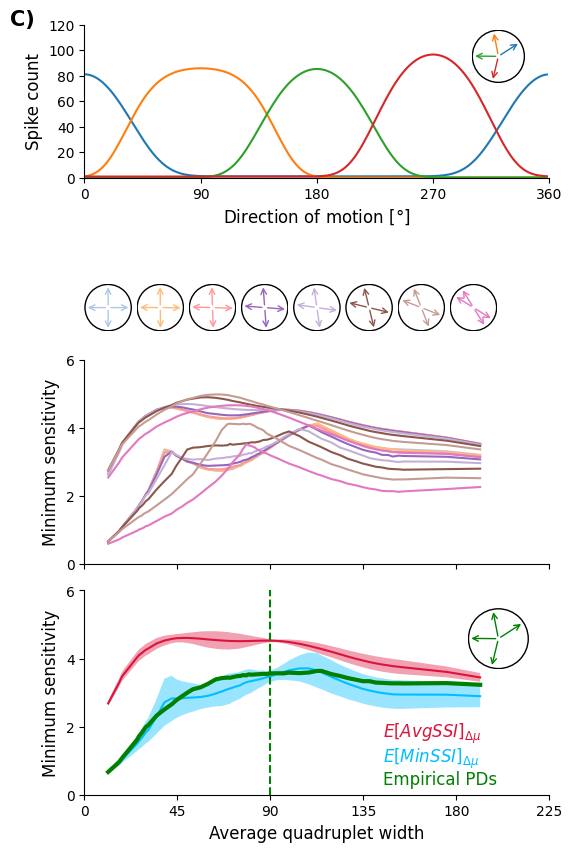

In [252]:
example = 125
data=np.load(output_dir+f'sabbah_prll_ssi_quad{example}.npz')
new_pds = data['new_pds']
prll_shifted_pars_het = data['prll_shifted_pars_het']
prll_ssis = data['prll_ssis']


# --- Settings ---
# Get the tab10 colors
all_colors = plt.get_cmap('tab20').colors  # tuple of 10 RGB colors
# The green color in tab10 is at index 1
colors = tuple(c for i, c in enumerate(all_colors) if i not in [0,2,4,5,6])


n_arrows = new_pds.shape[0]  # total arrow plots
angles_array = prll_shifted_pars_het[:, bio_idx, :, 1]  # shape (18, 4)

fig = plt.figure(figsize=(6, 10))
gs = GridSpec(5, 9, figure=fig, height_ratios=[3, 1,1, 4, 4], hspace=0.2, wspace=0.1)

ax_quad = fig.add_subplot(gs[0, :])
lines = ax_quad.plot(stim, np.array([ssiMod.FTVM_dx(stim, *pars) for pars in prll_shifted_pars_het[0,bio_idx]]).T)
example_angles = data_dict['all_quad_pars'][example, bio_idx, :,1]  # degrees

# --- Add inset in the bottom prll_ssis plot ---
# ax is the main SSI axes from previous code
axins = inset_axes(ax_quad, width="35%", height="35%", loc='upper right',
        bbox_to_anchor=(0.125, 0.15, 1, 1), bbox_transform = ax_quad.transAxes, borderpad=2)

# Circle in inset
axins.add_patch(plt.Circle((0,0), 1, fill=False, lw=1))

for i,a in enumerate(np.deg2rad(example_angles)):
    x, y = np.cos(a), np.sin(a)
    arrow = FancyArrowPatch(
        (0,0), (x,y),
        arrowstyle='->',
        mutation_scale=10,
        linewidth=1,
        color= lines[i].get_color(),  # black arrows
        fill=False
    )
    axins.add_patch(arrow)

axins.set_aspect('equal')
axins.set_xlim(-1.03, 1.03)
axins.set_ylim(-1.03, 1.03)
axins.axis('off')

ax_quad.set_xticks(np.arange(0,361,90))
ax_quad.set_yticks(np.arange(0,121,20))
ax_quad.set_xlim(0,360)
ax_quad.set_ylim(0,120)
ax_quad.set_xlabel('Direction of motion [$\degree$]', size = 12)
ax_quad.set_ylabel('Spike count', size = 12)
ax_quad.text(-0.16, 1.1, 'C)', ha='left', va='top', transform=ax_quad.transAxes, fontweight='bold', fontsize = 15)


# --- Top 2 rows: arrow plots ---
for i in range(n_arrows):
    row = i // 9 + 2
    col = i % 9
    ax = fig.add_subplot(gs[row, col])

    ax.add_patch(plt.Circle((0,0), 1, fill=False, lw=1))

    for a in np.deg2rad(angles_array[i]):
        x, y = np.cos(a), np.sin(a)
        arrow = FancyArrowPatch(
            (0,0), (x,y),
            arrowstyle='->',
            mutation_scale=10,
            linewidth=1,
            color=colors[i],
            fill=False
        )
        ax.add_patch(arrow)

    ax.set_aspect('equal')
    ax.set_xlim(-1.025, 1.025)
    ax.set_ylim(-1.025, 1.025)
    ax.axis('off')

    
ax0 = fig.add_subplot(gs[3, :])
for i in range(n_arrows):
    ax0.plot(data_dict['all_quad_fwhm'][example].mean(axis=1), prll_ssis[i].min(axis=1), 
            color=colors[i])
    
    ax0.plot(data_dict['all_quad_fwhm'][example].mean(axis=1), prll_ssis[i].mean(axis=1), 
            color=colors[i])

ax0.set_ylim(0, 6)
ax0.set_yticks(np.arange(0,6.1,2))
ax0.set_xlim(0,220)
ax0.set_ylabel('Minimum sensitivity', size = 12)
ax0.set_xticks(np.arange(0,226,45))
ax0.set_xticklabels([])


# --- Bottom row: prll_ssis lines ---
ax = fig.add_subplot(gs[4, :])



ax.plot(data_dict['all_quad_fwhm'][example].mean(axis=1), prll_ssis.mean(axis=2).mean(axis=0), 
        color='Crimson', label = r'$E[AvgSSI]_{\Delta\mu}$')

ax.fill_between(data_dict['all_quad_fwhm'][example].mean(axis=1), \
                prll_ssis.mean(axis=2).mean(axis=0)-prll_ssis.mean(axis=2).std(axis=0),\
                prll_ssis.mean(axis=2).mean(axis=0)+prll_ssis.mean(axis=2).std(axis=0),
        color='Crimson', alpha = 0.4, edgecolor = None)

ax.plot(data_dict['all_quad_fwhm'][example].mean(axis=1), prll_ssis.min(axis=2).mean(axis=0), 
        color='deepskyblue', label = r'$E[MinSSI]_{\Delta\mu}$')

ax.fill_between(data_dict['all_quad_fwhm'][example].mean(axis=1), \
                prll_ssis.min(axis=2).mean(axis=0)-prll_ssis.min(axis=2).std(axis=0),\
                prll_ssis.min(axis=2).mean(axis=0)+prll_ssis.min(axis=2).std(axis=0),
        color='deepskyblue', alpha = 0.4, edgecolor = None)
    
# Optional: overlay other reference lines
ax.axvline(data_dict['all_quad_fwhm'][example, bio_idx].mean(), color='green', ls='dashed')
ax.plot(data_dict['all_quad_fwhm'][example].mean(axis=1), 
        data_dict['all_ssis'][example].min(axis=1), color='green', lw=3, label = 'Empirical PDs')

ax.set_ylim(0, 6)
ax.set_yticks(np.arange(0,6.1,2))
ax.set_xlim(0,220)
ax.set_xticks(np.arange(0,226,45))
ax.set_xlabel('Average quadruplet width', size =12)
ax.set_ylabel('Minimum sensitivity', size = 12)
ax.legend(handlelength = 0, labelcolor = 'linecolor', frameon=0, fontsize = 12, loc = (0.6, 0.),\
         labelspacing = 0.)
# --- Add inset in the bottom prll_ssis plot ---
# ax is the main SSI axes from previous code
axins = inset_axes(ax, width="30%", height="30%", loc='upper right', \
                   bbox_to_anchor = (0.1,0.05,1,1), bbox_transform = ax.transAxes, borderpad=2)

# Circle in inset
axins.add_patch(plt.Circle((0,0), 1, fill=False, lw=1))

# Example 4 green arrows
example_angles = data_dict['all_quad_pars'][example, bio_idx, :,1]  # degrees
for a in np.deg2rad(example_angles):
    x, y = np.cos(a), np.sin(a)
    arrow = FancyArrowPatch(
        (0,0), (x,y),
        arrowstyle='->',
        mutation_scale=10,
        linewidth=1,
        color='green',  # black arrows
        fill=False
    )
    axins.add_patch(arrow)

axins.set_aspect('equal')
axins.set_xlim(-1.025, 1.025)
axins.set_ylim(-1.025, 1.025)
axins.axis('off')

fig.savefig(output_dir+f'Sabbah_minSSI_quad{example}.jpg', bbox_inches = 'tight', dpi = 300)

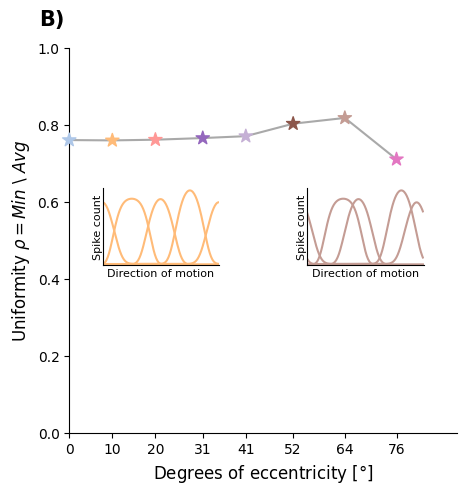

In [335]:
# ------------------------- UNIFORMITY AS FCN OF ECCENTRICITY PLOT -------------------------

example = 125
data=np.load(output_dir+f'sabbah_prll_ssi_quad{example}.npz')
new_pds = data['new_pds']
prll_shifted_pars_het = data['prll_shifted_pars_het']
prll_ssis = data['prll_ssis']
ecc = data['x0']

# Get the tab10 colors
all_colors = plt.get_cmap('tab20').colors  # tuple of 10 RGB colors
# The green color in tab10 is at index 1
colors = tuple(c for i, c in enumerate(all_colors) if i not in [0,2,4,5,6])

fig, ax = plt.subplots(figsize=(5,5))

ax.plot(np.around(np.rad2deg(2*np.arcsin(ecc))), \
         prll_ssis[:,bio_idx].min(axis=1)/prll_ssis[:,bio_idx].mean(axis=1), c='darkgrey')
ax.set_xticks(np.around(np.rad2deg(2*np.arcsin(ecc))))

ax.scatter(np.around(np.rad2deg(2*np.arcsin(ecc))),\
            prll_ssis[:,bio_idx].min(axis=1)/prll_ssis[:,bio_idx].mean(axis=1), \
            c=colors[:len(ecc)], marker='*',s = 100, clip_on=0, zorder = 10)


axins1 = inset_axes(ax, width="30%", height="20%", loc='lower left',
        bbox_to_anchor=(0.05, 0.4, 1, 1), bbox_transform = ax.transAxes, borderpad=1)

axins1.plot(stim, data['prll_tcs'][1,bio_idx].T, color = colors[1])
axins1.set_xticks([])
axins1.set_yticks([])
axins1.set_xlim(0,360)
axins1.set_ylim(0,100)
axins1.set_xlabel('Direction of motion', size = 8)
axins1.set_ylabel('Spike count', size = 8)
axins1.xaxis.set_label_coords(0.5, -0.05)
axins1.yaxis.set_label_coords(0, 0.5)


axins2 = inset_axes(ax, width="30%", height="20%", loc='lower right',
        bbox_to_anchor=(-0.05, 0.4, 1, 1), bbox_transform = ax.transAxes, borderpad=1)

axins2.plot(stim, data['prll_tcs'][-2,bio_idx].T, color = colors[data['prll_tcs'].shape[0]-2])
axins2.set_xticks([])
axins2.set_yticks([])
axins2.set_xlim(0,360)
axins2.set_ylim(0,100)
axins2.set_xlabel('Direction of motion', size = 8)
axins2.set_ylabel('Spike count', size = 8)
axins2.xaxis.set_label_coords(0.5, -0.05)
axins2.yaxis.set_label_coords(0, 0.5)

# def draw_arrow(ax, x0, y0, theta, length,
#                color='k', lw=1, scale=15, style='->', open_head=True):

draw_arrow(ax, 16.5, 0.525, 0, 6, color = 'darkgrey', lw=2, scale = 15, style = '->')


ax.set_xlim(0,90)
ax.set_ylim(0,1)

ax.set_xlabel(r'Degrees of eccentricity [$\degree$]', size = 12)
ax.set_ylabel(r'Uniformity $\rho = Min ~\backslash ~Avg$', size = 12)

ax.text(-7, 1.1, 'B)', ha='left', va='top', fontweight='bold', fontsize = 15)

fig.savefig(output_dir + 'Ecc_v_unif.jpg', dpi = 300, bbox_inches = 'tight')

In [325]:
new_params = np.tile(np.copy(data_dict['all_quad_pars'][:,bio_idx])[None, :,:,:], \
                     (new_pds.shape[0],1,1,1))
new_params[:,:,:,1] = new_pds[:,None,:]
new_tcs = np.array([np.array([np.array([ssiMod.FTVM_dx(stim, *pars) for pars in quad]) \
                              for quad in pop]) for pop in new_params])

# sabbah_ssis = np.array([np.array([ssiMod.MC_SSI(quad_tc) for quad_tc in tqdm(pop)]) for pop in tqdm(new_tcs)])

from concurrent.futures import ProcessPoolExecutor

# for bio quads, you can safely put up to 7 workers, maybe even 8, 
# cutting the computatin time down to an 30mins

def compute_pop(pop):
    with ProcessPoolExecutor(max_workers=4) as executor:
        res = list(executor.map(ssiMod.MC_SSI, pop))
    return np.array(res)

sabbah_ssis = np.array([compute_pop(pop) for pop in tqdm(new_tcs)])



  0%|          | 0/8 [00:00<?, ?it/s]

array([0.        , 0.08838835, 0.1767767 , 0.26516504, 0.35355339,
       0.44194174, 0.53033009, 0.61871843])

In [332]:
np.savez(output_dir+'sabbah_all_quads.npz', eccentricity = x0_arr, all_sabbah_pars = new_params, \
         all_sabbah_tcs = new_tcs, all_sabbah_ssis = sabbah_ssis)

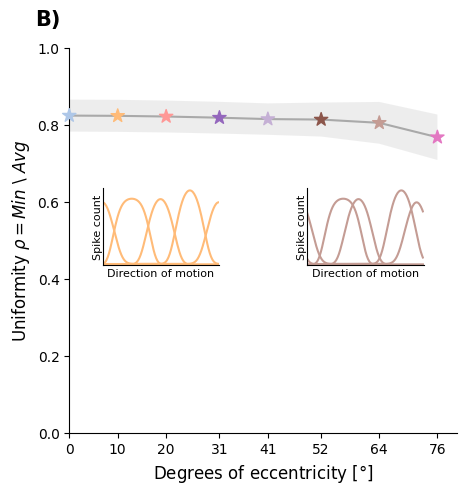

In [345]:
ro = sabbah_ssis.min(axis=2)/sabbah_ssis.mean(axis=2)

all_colors = plt.get_cmap('tab20').colors  # tuple of 10 RGB colors
# The green color in tab10 is at index 1
colors = tuple(c for i, c in enumerate(all_colors) if i not in [0,2,4,5,6])

fig, ax = plt.subplots(figsize=(5,5))

ax.plot(np.around(np.rad2deg(2*np.arcsin(ecc))), \
         ro.mean(axis=1), c='darkgrey')

ax.fill_between(np.around(np.rad2deg(2*np.arcsin(ecc))), \
         ro.mean(axis=1)-ro.std(axis=1), ro.mean(axis=1)+ro.std(axis=1), \
         color='darkgrey', alpha = 0.2, edgecolor = None)


ax.set_xticks(np.around(np.rad2deg(2*np.arcsin(ecc))))

ax.scatter(np.around(np.rad2deg(2*np.arcsin(ecc))),\
            ro.mean(axis=1), \
            c=colors[:len(ecc)], marker='*',s = 100, clip_on=0, zorder = 10)


axins1 = inset_axes(ax, width="30%", height="20%", loc='lower left',
        bbox_to_anchor=(0.05, 0.4, 1, 1), bbox_transform = ax.transAxes, borderpad=1)

axins1.plot(stim, data['prll_tcs'][1,bio_idx].T, color = colors[1])
axins1.set_xticks([])
axins1.set_yticks([])
axins1.set_xlim(0,360)
axins1.set_ylim(0,100)
axins1.set_xlabel('Direction of motion', size = 8)
axins1.set_ylabel('Spike count', size = 8)
axins1.xaxis.set_label_coords(0.5, -0.05)
axins1.yaxis.set_label_coords(0, 0.5)


axins2 = inset_axes(ax, width="30%", height="20%", loc='lower right',
        bbox_to_anchor=(-0.05, 0.4, 1, 1), bbox_transform = ax.transAxes, borderpad=1)

axins2.plot(stim, data['prll_tcs'][-2,bio_idx].T, color = colors[data['prll_tcs'].shape[0]-2])
axins2.set_xticks([])
axins2.set_yticks([])
axins2.set_xlim(0,360)
axins2.set_ylim(0,100)
axins2.set_xlabel('Direction of motion', size = 8)
axins2.set_ylabel('Spike count', size = 8)
axins2.xaxis.set_label_coords(0.5, -0.05)
axins2.yaxis.set_label_coords(0, 0.5)

# def draw_arrow(ax, x0, y0, theta, length,
#                color='k', lw=1, scale=15, style='->', open_head=True):

draw_arrow(ax, 16.5, 0.525, 0, 6, color = 'darkgrey', lw=2, scale = 15, style = '->')


ax.set_xlim(0,80)
ax.set_ylim(0,1)

ax.set_xlabel(r'Degrees of eccentricity [$\degree$]', size = 12)
ax.set_ylabel(r'Uniformity $\rho = Min ~\backslash ~Avg$', size = 12)

ax.text(-7, 1.1, 'B)', ha='left', va='top', fontweight='bold', fontsize = 15)

fig.savefig(output_dir+'sabbah_all_quads_ecc_v_ro.jpg', dpi = 300, bbox_inches = 'tight')